# 04 — Region Growing cổ điển

Region Growing bắt đầu từ các hạt giống (seed), xét pixel lân cận và kết nạp pixel `q` nếu:

\[\|I(q)-\mu_i\| \le T\]

Trong đó `mu_i` là trung bình hiện tại của vùng. Sau khi kết nạp, thuật toán cập nhật tổng, số pixel và trung bình vùng.

Notebook kiểm tra hai cách duyệt:
- `stack`: LIFO, phần tử vào sau được xử lý trước.
- `queue`: FIFO, phần tử vào trước được xử lý trước.

Cả hai dùng lân cận 4 và trả `-1` cho pixel chưa được gán.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt
from cv_bt2.corner import *
from cv_bt2.data.synthetic import *
from cv_bt2.visualization import plot_corners, plot_labels

OUT = ROOT / "outputs" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

from cv_bt2.segmentation import region_growing_classic, srg
from cv_bt2.segmentation.metrics import count_regions, partition_difference

Project root: /mnt/data/Computer_Vision_BT2


## 1. Ảnh có ba vùng và ba seed

Ảnh thử nghiệm có ba dải mức xám, cộng thêm biến thiên nhẹ và nhiễu. Các seed được đặt trong ba dải khác nhau.

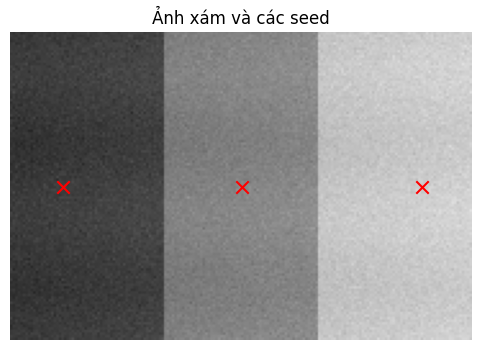

In [2]:
img=segmentation_scene(size=(120,180),random_state=42,noise=5)
seeds=[(60,20),(60,90),(60,160)]
plt.figure(figsize=(9,4)); plt.imshow(img,cmap="gray",vmin=0,vmax=255)
plt.scatter([x for y,x in seeds],[y for y,x in seeds],c="red",marker="x",s=80)
plt.title("Ảnh xám và các seed"); plt.axis("off"); plt.show()

## 2. Chạy Stack và Queue

Thứ tự duyệt có thể ảnh hưởng quá trình cập nhật trung bình vùng. Ta đo số pixel chưa được gán, số vùng và khác biệt phân vùng sau khi bỏ qua khác biệt ID nhãn.

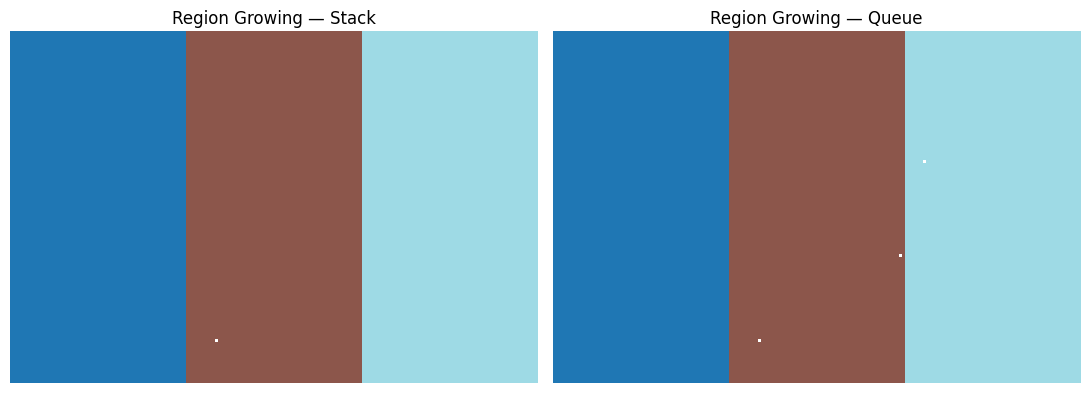

Stack regions= 3 unassigned= 1 unassigned % = 0.005
Queue regions= 3 unassigned= 3 unassigned % = 0.014
Khác biệt Stack/Queue sau ánh xạ nhãn tối ưu: {'common_labeled_pixels': 21597, 'different_partition_pixels': 0, 'different_percent_of_common': 0.0, 'unassigned_a': 1, 'unassigned_b': 3}


In [3]:
T=25
labels_stack=region_growing_classic(img,seeds,T,order="stack")
labels_queue=region_growing_classic(img,seeds,T,order="queue")
fig,ax=plt.subplots(1,2,figsize=(11,4))
plot_labels(labels_stack,ax=ax[0],title="Region Growing — Stack")
plot_labels(labels_queue,ax=ax[1],title="Region Growing — Queue")
plt.tight_layout(); plt.show()
for name,labels in [("Stack",labels_stack),("Queue",labels_queue)]:
    print(name,"regions=",count_regions(labels),"unassigned=",int((labels<0).sum()),
          "unassigned % =",round(100*np.mean(labels<0),3))
print("Khác biệt Stack/Queue sau ánh xạ nhãn tối ưu:",partition_difference(labels_stack,labels_queue))

## 3. So sánh Region Growing với SRG

SRG sử dụng hàng đợi ưu tiên và không dùng ngưỡng đồng nhất `T`; trong thuật toán SRG mọi pixel liên thông sẽ được gán nhãn. Khi so sánh cần báo cáo riêng pixel chưa gán của Region Growing, vì so sánh nhãn chỉ trên phần cả hai cùng gán không thể hiện phần bị bỏ trống.

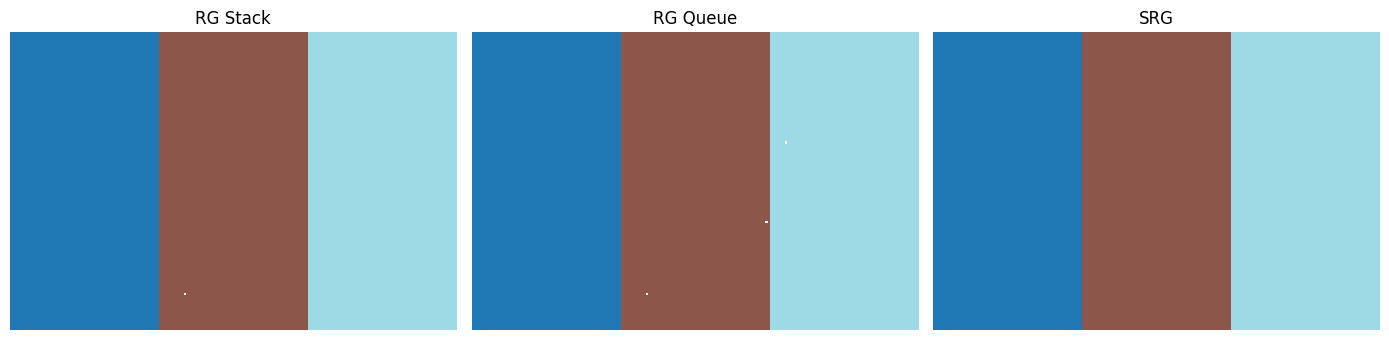

Stack vs SRG: {'common_labeled_pixels': 21599, 'different_partition_pixels': 0, 'different_percent_of_common': 0.0, 'unassigned_a': 1, 'unassigned_b': 0}
Queue vs SRG: {'common_labeled_pixels': 21597, 'different_partition_pixels': 0, 'different_percent_of_common': 0.0, 'unassigned_a': 3, 'unassigned_b': 0}


In [4]:
labels_srg,boundary_srg=srg(img,seeds,connectivity=4,stale="lazy",tie="insertion")
fig,ax=plt.subplots(1,3,figsize=(14,4))
plot_labels(labels_stack,ax=ax[0],title="RG Stack")
plot_labels(labels_queue,ax=ax[1],title="RG Queue")
plot_labels(labels_srg,ax=ax[2],title="SRG")
plt.tight_layout(); plt.show()
print("Stack vs SRG:",partition_difference(labels_stack,labels_srg))
print("Queue vs SRG:",partition_difference(labels_queue,labels_srg))

## 4. Quét ngưỡng T

T nhỏ làm tiêu chí đồng nhất nghiêm ngặt nên nhiều pixel có thể còn `-1`. T tăng có thể kết nạp nhiều pixel hơn, nhưng quá lớn có nguy cơ vùng lan qua biên cường độ. Đo số pixel chưa gán và diện tích vùng lớn nhất.

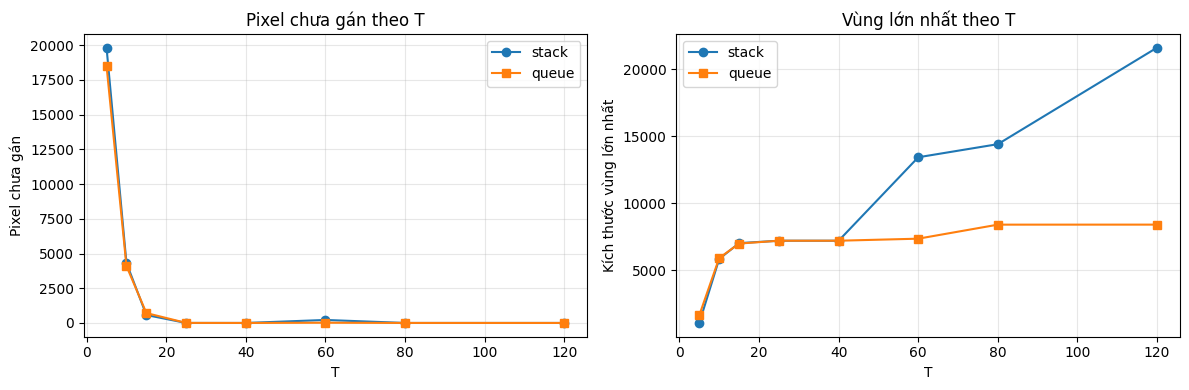


 STACK
{'T': 5, 'unassigned': 19833, 'largest_region': 1069, 'regions': 3}
{'T': 10, 'unassigned': 4322, 'largest_region': 5845, 'regions': 3}
{'T': 15, 'unassigned': 572, 'largest_region': 7020, 'regions': 3}
{'T': 25, 'unassigned': 1, 'largest_region': 7200, 'regions': 3}
{'T': 40, 'unassigned': 0, 'largest_region': 7200, 'regions': 3}
{'T': 60, 'unassigned': 216, 'largest_region': 13422, 'regions': 3}
{'T': 80, 'unassigned': 0, 'largest_region': 14399, 'regions': 3}
{'T': 120, 'unassigned': 0, 'largest_region': 21598, 'regions': 3}

 QUEUE
{'T': 5, 'unassigned': 18511, 'largest_region': 1640, 'regions': 3}
{'T': 10, 'unassigned': 4104, 'largest_region': 5908, 'regions': 3}
{'T': 15, 'unassigned': 712, 'largest_region': 6988, 'regions': 3}
{'T': 25, 'unassigned': 3, 'largest_region': 7200, 'regions': 3}
{'T': 40, 'unassigned': 0, 'largest_region': 7200, 'regions': 3}
{'T': 60, 'unassigned': 17, 'largest_region': 7352, 'regions': 3}
{'T': 80, 'unassigned': 1, 'largest_region': 8398, 

In [5]:
thresholds=[5,10,15,25,40,60,80,120]
sweep={"stack":[],"queue":[]}
for order in sweep:
    for threshold in thresholds:
        lab=region_growing_classic(img,seeds,threshold,order=order)
        sizes=[int(np.sum(lab==rid)) for rid in np.unique(lab) if rid>=0]
        sweep[order].append({"T":threshold,"unassigned":int(np.sum(lab<0)),
                             "largest_region":max(sizes) if sizes else 0,
                             "regions":count_regions(lab)})
fig,ax=plt.subplots(1,2,figsize=(12,4))
for order,marker in [("stack","o"),("queue","s")]:
    ax[0].plot(thresholds,[x["unassigned"] for x in sweep[order]],marker=marker,label=order)
    ax[1].plot(thresholds,[x["largest_region"] for x in sweep[order]],marker=marker,label=order)
ax[0].set_xlabel("T"); ax[0].set_ylabel("Pixel chưa gán"); ax[0].set_title("Pixel chưa gán theo T")
ax[1].set_xlabel("T"); ax[1].set_ylabel("Kích thước vùng lớn nhất"); ax[1].set_title("Vùng lớn nhất theo T")
for a in ax: a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()
for order in sweep:
    print("\n",order.upper())
    for row in sweep[order]: print(row)

## 5. Kết luận

- `T` là ngưỡng chấp nhận sai khác so với trung bình vùng hiện tại.
- Khi `T` quá nhỏ, vùng khó phát triển và ảnh có nhiều pixel không gán nhãn.
- Khi `T` quá lớn, vùng có thể lan qua ranh giới giữa hai cấu trúc.
- Stack và Queue khác nhau ở thứ tự xử lý pixel; vì trung bình vùng thay đổi sau mỗi lần kết nạp, chúng có thể cho kết quả khác.
- Kết quả phụ thuộc cả vị trí/số lượng seed và thứ tự duyệt.